# Imports

In [1]:
import os

os.environ["KERAS_BACKEND"] = "torch"
import keras
import torch

In [2]:
keras.mixed_precision.set_global_policy('mixed_float16')

In [37]:
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tqdm.notebook as tqdm
import transformers

In [4]:
print('CUDA:', torch.version.cuda)
print('GPU:', torch.cuda.is_available())

CUDA: 12.8
GPU: True


# Choose the dataset

Get the dataset from [here](https://tatoeba.org/en/downloads). Preferably use russian to english translations.

In [5]:
df = pd.read_csv("../../data/rnn_seq2seq/rus-eng.tsv", sep="\t", usecols=[1, 3], names=["ru", "en"])

In [6]:
df

,ru,en
0,Один раз в жизни я делаю хорошее дело... И оно...,For once in my life I'm doing a good deed... A...
1,Давайте что-нибудь попробуем!,Let's try something.
2,Мне пора идти спать.,I have to go to sleep.
3,Что ты делаешь?,What are you doing?
4,Что ты делаешь?,What do you make?
...,...,...
830313,Меня не поставили в известность.,I was not informed.
830314,Меня не поставили в известность.,I have not been informed.
830315,Она не поставила меня в известность.,She didn't inform me.
830316,Мне просто надо было увидеть это самому.,I just had to see this for myself.


# Tokenizer

Train your own tokenizer on a corpus for the languages you've chosen or load a pretrained tokenizer. The tokenizer must allow BOS, EOS and PAD tokens.

In [7]:
tokenizer: transformers.T5TokenizerFast = transformers.AutoTokenizer.from_pretrained("lmqg/mt5-base-ruquad-ae-trimmed-50000")

In [8]:
tokenizer.encode("Привет, мир!"), tokenizer.encode("Hello, world!")

([1479, 10516, 5, 5959, 53, 1], [11255, 5, 2604, 53, 1])

In [9]:
tokenizer.vocab_size

50001

In [10]:
tokenizer.bos_token_id, tokenizer.eos_token_id, tokenizer.pad_token_id

(None, 1, 0)

In [11]:
tokenizer.add_special_tokens({'bos_token': '<bos>'})
tokenizer.bos_token_id

50002

In [12]:
tokens_ru = tokenizer(df["ru"].to_list(), add_special_tokens=False)["input_ids"]

In [13]:
tokens_en = tokenizer(df["en"].to_list(), add_special_tokens=False)["input_ids"]

In [14]:
tokens_ru_len = [len(tokens) for tokens in tokens_ru]
tokens_en_len = [len(tokens) for tokens in tokens_en]

<Axes: ylabel='Count'>

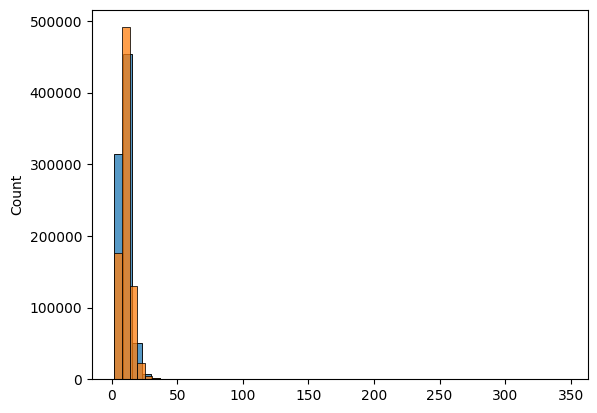

In [15]:
sns.histplot(tokens_en_len, bins=50)
sns.histplot(tokens_ru_len, bins=50)

In [16]:
np.quantile(tokens_ru_len, 0.95)

np.float64(18.0)

In [17]:
np.quantile(tokens_en_len, 0.95)

np.float64(17.0)

# Dataset

Since the dataset is rather large, you can omit the validation dataset and just use a set of test sentences after the training.

Create a dataset that returns the following
* A pair of tensors `((None, L), (None, P))` -- input sequence of tokens and output sequence of tokens to be fed into decoder (this should start with the BOS token)
* A tensor `(None, P)` -- output sequence of tokens to be predicted (this should end with EOS token)

In [18]:
class Seq2SeqDataset(keras.utils.PyDataset):
    def __init__(
        self,
        input_sequences,
        max_seq_length_input: int,
        output_sequences,
        max_seq_length_output: int,
        tokenizer: transformers.PreTrainedTokenizerBase,
        batch_size: int = 128,
        shuffle: bool = True,
        rng: np.random.Generator | None = None,
        **kwargs,
    ):
        super().__init__(**kwargs)

        if rng is None:
            rng = np.random.default_rng()

        self.max_seq_lenth_input = max_seq_length_input
        self.max_seq_lenth_output = max_seq_length_output

        input_seq = []
        output_seq = []

        for ru, en in zip(input_sequences, output_sequences):
            if (
                len(ru) > self.max_seq_lenth_input
                or len(en) > self.max_seq_lenth_output
            ):
                continue
            input_seq.append(ru)
            output_seq.append(en)

        self.input = input_seq
        self.output = output_seq

        input_lost = len(input_sequences) - len(input_seq)
        output_lost = len(output_sequences) - len(output_seq)

        print(
            f"{input_lost} ({input_lost / len(input_sequences) if input_lost != 0 else 0:.1%}) input lost due to len limiter"
        )
        print(
            f"{output_lost} ({output_lost / len(output_sequences) if input_lost != 0 else 0:.1%}) output lost due to len limiter"
        )

        self.batch_size = batch_size
        self.shuffle = shuffle
        self.rng = rng
        self.tokenizer = tokenizer
        self.indices = np.arange(len(self.input))

    def __len__(self) -> int:
        return int(-(-len(self.indices) / self.batch_size))

    def __getitem__(self, index):
        start = index * self.batch_size
        end = min(start + self.batch_size, len(self.indices))
        batch_indices = self.indices[start:end]

        encoder_input_tokens = [self.input[i] for i in batch_indices]
        decoder_input_tokens = [
            [self.tokenizer.bos_token_id] + self.output[i] for i in batch_indices
        ]
        decoder_output_tokens = [
            self.output[i] + [self.tokenizer.eos_token_id] for i in batch_indices
        ]

        assert isinstance(self.tokenizer.pad_token_id, int)

        encoder_input = keras.utils.pad_sequences(
            encoder_input_tokens,
            maxlen=self.max_seq_lenth_input,
            padding="post",
            value=self.tokenizer.pad_token_id,
        )
        decoder_input = keras.utils.pad_sequences(
            decoder_input_tokens,
            maxlen=self.max_seq_lenth_output,
            padding="post",
            value=self.tokenizer.pad_token_id,
        )
        decoder_output = keras.utils.pad_sequences(
            decoder_output_tokens,
            maxlen=self.max_seq_lenth_output,
            padding="post",
            value=self.tokenizer.pad_token_id,
        )

        mask = (decoder_output != self.tokenizer.pad_token_id).astype(np.float32)

        return (encoder_input, decoder_input), decoder_output, mask

    def on_epoch_begin(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

In [19]:
train_ds = Seq2SeqDataset(tokens_ru, 18, tokens_en, 17, tokenizer, batch_size=128)

52777 (6.4%) input lost due to len limiter
52777 (6.4%) output lost due to len limiter


In [20]:
val_translations = [
    ("Привет, как дела?", "Hi, how are you?"),
    ("Я люблю читать книги.", "I love reading books."),
    ("Сегодня хорошая погода.", "The weather is nice today."),
    ("Он не пришёл на встречу.", "He didn't come to the meeting."),
    ("Завтра мы поедем в Москву.", "We will go to Moscow tomorrow."),
    ("Мы поедем в Москву завтра.", "We will go to Moscow tomorrow."),
    ("Она готовит ужин на кухне.", "She is cooking dinner in the kitchen."),
    ("Мне нравится этот фильм.", "I like this movie."),
    ("Дети играют во дворе.", "The children are playing in the yard."),
    ("Я не знаю, что делать.", "I don't know what to do."),
    ("Этот дом был построен в прошлом году.", "This house was built last year."),
    ("В прошлом году был построен этот дом.", "This house was built last year."),
    ("Ты знаешь, как подстричься?", "Do you know how to get your hair cut?"),
    ("Ты знаешь, как пройти на пляж?", "Do you know how to get to the beach?"),
    ("Ты знаешь, как ездить на лошади?", "Do you know how to ride a horse?"),
]

In [21]:
val_ru_tokens = []
val_en_tokens = []

for ru, en in val_translations:
    val_ru_tokens.append(tokenizer.encode(ru))
    val_en_tokens.append(tokenizer.encode(en))

In [22]:
val_ds = Seq2SeqDataset(val_ru_tokens, 18, val_en_tokens, 17, tokenizer, batch_size=10)

0 (0.0%) input lost due to len limiter
0 (0.0%) output lost due to len limiter


# Model

Create a model for training. The model should have two inputs: input sequence `(None, L)` and output sequence`(None, P)`. The model output is a single tensor `(None, P)` logits (or probabilities) of the next token predicted for each input one. The model MUST have decoder only architecture.

In [23]:
class TokenAndPositionEmbedding(keras.layers.Layer):
    def __init__(
        self, maxlen: int, vocab_size: int, embed_dim: int, pad_token_id: int, **kwargs
    ):
        super().__init__(**kwargs)
        self.maxlen = maxlen
        self.token_emb = keras.layers.Embedding(vocab_size, embed_dim, mask_zero=True)
        self.pos_emb = keras.layers.Embedding(maxlen, embed_dim)
        self.pad_token_id = pad_token_id
        self.cls_token = self.add_weight(
            shape=(1, 1, embed_dim),
            initializer="random_normal",
            trainable=True,
            name="cls_token",
        )

    def call(self, x):
        seq_len = keras.ops.shape(x)[1]
        positions = keras.ops.arange(seq_len, dtype="int32")
        positions = keras.ops.expand_dims(positions, 0)

        x_emb = self.token_emb(x) + self.pos_emb(positions)

        batch_size = keras.ops.shape(x)[0]
        cls_tokens = keras.ops.broadcast_to(
            self.cls_token, (batch_size, 1, x_emb.shape[-1])
        )
        x_emb = keras.ops.concatenate([cls_tokens, x_emb], axis=1)
        return x_emb

    def compute_mask(self, inputs, previous_mask=None):
        token_mask = keras.ops.not_equal(inputs, self.pad_token_id)

        cls_mask = keras.ops.ones_like(token_mask[:, :1])

        combined_mask = keras.ops.concatenate([cls_mask, token_mask], axis=1)
        return combined_mask

In [24]:
class TransformerBlock(keras.layers.Layer):
    def __init__(self, embed_dim: int, num_heads: int, ff_dim: int, **kwargs):
        super().__init__(**kwargs)
        self.att = keras.layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embed_dim // num_heads
        )
        self.ffn = keras.Sequential(
            [
                keras.layers.Dense(ff_dim, activation="gelu"),
                keras.layers.Dense(embed_dim),
            ]
        )
        self.norm1 = keras.layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = keras.layers.LayerNormalization(epsilon=1e-6)

    def call(self, x, training=False):
        attn_out = self.att(x, x, use_causal_mask=True)
        x = self.norm1(x + attn_out)
        ffn_out = self.ffn(x, training=training)
        x = self.norm2(x + ffn_out)
        return x

    def compute_mask(self, inputs, previous_mask=None):
        return previous_mask

In [25]:
def get_model(
    vocab_size: int,
    embedding_size: int,
    max_length_source: int,
    max_length_target: int,
    num_blocks: int,
    num_heads: int,
    pad_token_id: int,
    name: str | None = None,
) -> keras.models.Model:
    """Creates a model with Transformer architecture for seq2seq.

    Arguments:
        vocab_size: size of the tokenizer vocabulary
        embedding_size: size of the internal mdoel representations
        max_length: maximal allowed sequence length for each of the input sequences
        num_blocks: number of transformer blocks
        num_heads: number of multi head attentions heads
        pad_token_id: id of the padding token
        name: the model name

    Returns:
        The model"""
    source_inputs = keras.Input(
        shape=(max_length_source,), dtype="int32", name="source"
    )
    target_inputs = keras.Input(
        shape=(max_length_target,), dtype="int32", name="target"
    )

    combined = keras.ops.concatenate([source_inputs, target_inputs], axis=1)

    max_length = max_length_source + max_length_target
    x = TokenAndPositionEmbedding(
        maxlen=max_length,
        vocab_size=vocab_size,
        embed_dim=embedding_size,
        pad_token_id=pad_token_id,
        name="embedding",
    )(combined)

    for i in range(num_blocks):
        x = TransformerBlock(
            embed_dim=embedding_size,
            num_heads=num_heads,
            ff_dim=embedding_size * 4,
            name=f"transformer_block_{i}",
        )(x)

    x_target = x[:, -max_length_target:, :]

    logits = keras.layers.Dense(vocab_size, name="output_projection")(x_target)

    return keras.Model(
        inputs=[source_inputs, target_inputs],
        outputs=logits,
        name=name,
    )

In [26]:
model = get_model(
    vocab_size=len(tokenizer.get_vocab()),
    embedding_size=256,
    max_length_source=train_ds.max_seq_lenth_input,
    max_length_target=train_ds.max_seq_lenth_output,
    num_blocks=4,
    num_heads=8,
    pad_token_id=tokenizer.pad_token_id,
    name="decoder_only_seq2seq"
)

In [48]:
class MaskedSparseCategoricalAccuracy(keras.metrics.Metric):
    def __init__(self, pad_token_id: int = 0, name="masked_accuracy", **kwargs):
        super().__init__(name=name, **kwargs)
        self.pad_token_id = pad_token_id
        self.correct = self.add_weight(name="correct", initializer="zeros")
        self.total = self.add_weight(name="total", initializer="zeros")

    def update_state(self, y_true, y_pred, sample_weight=None):
        preds = keras.ops.argmax(y_pred, axis=-1)
        mask = keras.ops.cast(keras.ops.not_equal(y_true, self.pad_token_id), "float32")
        correct = keras.ops.cast(keras.ops.equal(preds, y_true), "float32") * mask
        self.correct.assign_add(keras.ops.sum(correct))
        self.total.assign_add(keras.ops.sum(mask))

    def result(self):
        return self.correct / (self.total + 1e-9)

    def reset_state(self):
        self.correct.assign(0.0)
        self.total.assign(0.0)

In [28]:
model.compile(
    optimizer=keras.optimizers.AdamW(3e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=[MaskedSparseCategoricalAccuracy(tokenizer.pad_token_id)],
)

In [29]:
model.summary()

Model: "decoder_only_seq2seq"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ source (InputLayer) │ (None, 18)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ target (InputLayer) │ (None, 17)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 35)        │          0 │ source[0][0],     │
│ (Concatenate)       │                   │            │ target[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 36, 256)   │ 12,809,984 │ concatenate[0][0] │
│ (TokenAndPositionE… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block_0 │ (None, 36, 256)   │    789,760 │ embedding[0][0]   │
│ (TransformerBlock)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block_1 │ (None, 36, 256)   │    789,760 │ transformer_bloc… │
│ (TransformerBlock)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block_2 │ (None, 36, 256)   │    789,760 │ transformer_bloc… │
│ (TransformerBlock)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block_3 │ (None, 36, 256)   │    789,760 │ transformer_bloc… │
│ (TransformerBlock)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 17, 256)   │          0 │ transformer_bloc… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output_projection   │ (None, 17, 50003) │ 12,850,771 │ get_item_1[0][0]  │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 28,819,795 (109.94 MB)

 Trainable params: 28,819,795 (109.94 MB)

 Non-trainable params: 0 (0.00 B)

# Training

Train your model using teacher forcing.

In [30]:
CHECKPOINT_DIR = Path(f"../../model_checkpoints/transformer_seq2seq/{datetime.now().strftime('%Y%m%d-%H%M%S')}")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

In [31]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        CHECKPOINT_DIR / "model_train_accuracy_{epoch}.keras",
        monitor="masked_accuracy",
        mode="max"
    ),
    keras.callbacks.ModelCheckpoint(
        CHECKPOINT_DIR / "model_val_accuracy_{epoch}.keras",
        monitor="val_masked_accuracy",
        mode="max",
    ),
]

In [32]:
model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=callbacks)

Epoch 1/10
6074/6074 ━━━━━━━━━━━━━━━━━━━━ 962s 158ms/step - loss: 0.8970 - masked_accuracy: 0.7216 - val_loss: 0.7510 - val_masked_accuracy: 0.8125
Epoch 2/10
6074/6074 ━━━━━━━━━━━━━━━━━━━━ 783s 129ms/step - loss: 0.4162 - masked_accuracy: 0.8391 - val_loss: 0.6188 - val_masked_accuracy: 0.8333
Epoch 3/10
6074/6074 ━━━━━━━━━━━━━━━━━━━━ 858s 141ms/step - loss: 0.3239 - masked_accuracy: 0.8659 - val_loss: 0.6624 - val_masked_accuracy: 0.8349
Epoch 4/10
6074/6074 ━━━━━━━━━━━━━━━━━━━━ 1065s 175ms/step - loss: 0.2720 - masked_accuracy: 0.8819 - val_loss: 0.6159 - val_masked_accuracy: 0.8559
Epoch 5/10
6074/6074 ━━━━━━━━━━━━━━━━━━━━ 1056s 174ms/step - loss: 0.2370 - masked_accuracy: 0.8932 - val_loss: 0.7796 - val_masked_accuracy: 0.7890
Epoch 6/10
6074/6074 ━━━━━━━━━━━━━━━━━━━━ 1068s 176ms/step - loss: 0.2112 - masked_accuracy: 0.9020 - val_loss: 0.7756 - val_masked_accuracy: 0.8482
Epoch 7/10
6074/6074 ━━━━━━━━━━━━━━━━━━━━ 970s 160ms/step - loss: 0.1916 - masked_accuracy: 0.9087 - val_loss

# Testing

Make a function for text translation. Translate some text and evaluate model performance.

In [33]:
def translate(
    text: str,
    tokenizer,
    model: keras.Model,
    max_source_length: int = 18,
    max_target_length: int = 17,
) -> str:
    '''Predicts `text`translation using the `model`.

    Arguments:
        text: text to be translated
        tokenizer: tokenizer to use
        model: model ot use
        max_len: maximum length of the prediction (in tokens)

    Returns:
        tranlated text'''
    pad_id = tokenizer.pad_token_id
    bos_id = tokenizer.bos_token_id
    eos_id = tokenizer.eos_token_id

    src_tokens = tokenizer.encode(text)
    if len(src_tokens) > max_source_length:
        src_tokens = src_tokens[-max_source_length:]
    src_padded = src_tokens + [pad_id] * (max_source_length - len(src_tokens))
    src = keras.ops.convert_to_tensor([src_padded], dtype="int32")

    generated: list[int] = []
    for _ in range(max_target_length - 1):
        target_ids = [bos_id] + generated
        target_padded = target_ids + [pad_id] * (max_target_length - len(target_ids))
        tgt = keras.ops.convert_to_tensor([target_padded], dtype="int32")

        logits = model([src, tgt], training=False)

        next_logits = logits[0, len(target_ids) - 1, :]
        next_id = int(keras.ops.argmax(next_logits))

        if next_id == eos_id or next_id == pad_id:
            break
        generated.append(next_id)

    return tokenizer.decode(generated, skip_special_tokens=True)

In [34]:
for ru, en in val_translations:
    pred = translate(ru, tokenizer, model)
    print(f"RU  : {ru}")
    print(f"REF : {en}")
    print(f"PRED: {pred}")
    print("-" * 60)

RU  : Привет, как дела?
REF : Hi, how are you?
PRED: Hi! How are you?
------------------------------------------------------------
RU  : Я люблю читать книги.
REF : I love reading books.
PRED: I like to read books.
------------------------------------------------------------
RU  : Сегодня хорошая погода.
REF : The weather is nice today.
PRED: The weather is good today.
------------------------------------------------------------
RU  : Он не пришёл на встречу.
REF : He didn't come to the meeting.
PRED: He absented himself from the meeting.
------------------------------------------------------------
RU  : Завтра мы поедем в Москву.
REF : We will go to Moscow tomorrow.
PRED: We will go to Moscow tomorrow.
------------------------------------------------------------
RU  : Мы поедем в Москву завтра.
REF : We will go to Moscow tomorrow.
PRED: We will go to Moscow tomorrow.
------------------------------------------------------------
RU  : Она готовит ужин на кухне.
REF : She is cooking dinn

# Bonus

Train the model using its own predictions as inputs. The probability to use the predicted tokens instead of the ones from the dataset should increase as the training progresses. Train for one or two epochs. Evaluate the model, does the model perform better?

In [35]:
self_forcing_model = get_model(
    vocab_size=len(tokenizer.get_vocab()),
    embedding_size=256,
    max_length_source=train_ds.max_seq_lenth_input,
    max_length_target=train_ds.max_seq_lenth_output,
    num_blocks=4,
    num_heads=8,
    pad_token_id=tokenizer.pad_token_id,
    name="own_predictions_as_inputs"
)

In [40]:
optimizer = torch.optim.Adam(self_forcing_model.parameters(), lr=3e-4)
loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True)

num_epochs = 2
total_steps = len(train_ds) * num_epochs
global_step = 0
MAX_TGT = 17
BOS = tokenizer.bos_token_id

self_forcing_model.train()

for epoch in range(num_epochs):
    loss_avg = keras.metrics.Mean()
    acc_avg = MaskedSparseCategoricalAccuracy(tokenizer.pad_token_id)

    for batch in train_ds:
        (x_src, x_tgt), y, sw = batch

        x_src = keras.ops.convert_to_tensor(x_src)
        x_tgt = keras.ops.convert_to_tensor(x_tgt)
        y = keras.ops.convert_to_tensor(y)

        bs = keras.ops.shape(x_tgt)[0]

        eps = min(0.5, 0.1 + 0.4 * global_step / total_steps)

        with torch.no_grad():
            logits_t = self_forcing_model([x_src, x_tgt], training=True)
            preds = keras.ops.argmax(logits_t, axis=-1)

        rand = keras.random.uniform((bs, MAX_TGT))
        use_pred = rand < eps
        use_pred = keras.ops.concatenate(
            [keras.ops.zeros((bs, 1), dtype="bool"), use_pred[:, 1:]], axis=1
        )
        preds_shifted = keras.ops.concatenate(
            [keras.ops.zeros((bs, 1), dtype="int32"), preds[:, :-1]], axis=1
        )
        x_tgt_mixed = keras.ops.where(use_pred, preds_shifted, x_tgt)
        x_tgt_mixed = keras.ops.concatenate([x_tgt[:, :1], x_tgt_mixed[:, 1:]], axis=1)

        optimizer.zero_grad()

        logits = self_forcing_model([x_src, x_tgt_mixed], training=True)
        loss = loss_fn(y, logits)

        loss.backward()  # type: ignore
        optimizer.step()

        loss_avg.update_state(loss)
        acc_avg.update_state(y, logits)
        global_step += 1

    print(
        f"Epoch {epoch + 1}/{num_epochs}: "
        f"loss={loss_avg.result():.4f}, acc={acc_avg.result():.4f}, eps={eps:.3f}"
    )

self_forcing_model.eval()

Exception ignored in: <function tqdm.__del__ at 0x0000012E34D9AE80>
Traceback (most recent call last):
  File "c:\Users\Yanovich\Documents\Projects\Cats\neural\.venv\Lib\site-packages\tqdm\std.py", line 1148, in __del__
    self.close()
  File "c:\Users\Yanovich\Documents\Projects\Cats\neural\.venv\Lib\site-packages\tqdm\notebook.py", line 279, in close
    self.disp(bar_style='danger', check_delay=False)
    ^^^^^^^^^
AttributeError: 'tqdm_notebook' object has no attribute 'disp'
Exception ignored in: <function tqdm.__del__ at 0x0000012E34D9AE80>
Traceback (most recent call last):
  File "c:\Users\Yanovich\Documents\Projects\Cats\neural\.venv\Lib\site-packages\tqdm\std.py", line 1148, in __del__
    self.close()
  File "c:\Users\Yanovich\Documents\Projects\Cats\neural\.venv\Lib\site-packages\tqdm\notebook.py", line 279, in close
    self.disp(bar_style='danger', check_delay=False)
    ^^^^^^^^^
AttributeError: 'tqdm_notebook' object has no attribute 'disp'


Epoch 1/2: loss=1.2200, acc=0.6656, eps=0.300
Epoch 2/2: loss=0.7097, acc=0.7698, eps=0.500


<Functional name=own_predictions_as_inputs, built=True>

In [41]:
for ru, en in val_translations:
    pred = translate(ru, tokenizer, self_forcing_model)
    print(f"RU  : {ru}")
    print(f"REF : {en}")
    print(f"PRED: {pred}")
    print("-" * 60)

RU  : Привет, как дела?
REF : Hi, how are you?
PRED: Hello, how are you?
------------------------------------------------------------
RU  : Я люблю читать книги.
REF : I love reading books.
PRED: I like reading books.
------------------------------------------------------------
RU  : Сегодня хорошая погода.
REF : The weather is nice today.
PRED: The weather is good today.
------------------------------------------------------------
RU  : Он не пришёл на встречу.
REF : He didn't come to the meeting.
PRED: He didn't come to the meeting.
------------------------------------------------------------
RU  : Завтра мы поедем в Москву.
REF : We will go to Moscow tomorrow.
PRED: Tomorrow we'll go to Moscow.
------------------------------------------------------------
RU  : Мы поедем в Москву завтра.
REF : We will go to Moscow tomorrow.
PRED: We'll go to Moscow tomorrow.
------------------------------------------------------------
RU  : Она готовит ужин на кухне.
REF : She is cooking dinner in th

In [49]:
simple_model = keras.models.load_model(
    "../../model_checkpoints/transformer_seq2seq/20261116-110311/model_train_accuracy_2.keras",
    custom_objects={
        "TokenAndPositionEmbedding": TokenAndPositionEmbedding,
        "TransformerBlock": TransformerBlock,
        "MaskedSparseCategoricalAccuracy": MaskedSparseCategoricalAccuracy
    },
)

c:\Users\Yanovich\Documents\Projects\Cats\neural\.venv\Lib\site-packages\keras\src\layers\layer.py:427: UserWarning: `build()` was called on layer 'embedding', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
c:\Users\Yanovich\Documents\Projects\Cats\neural\.venv\Lib\site-packages\keras\src\layers\layer.py:427: UserWarning: `build()` was called on layer 'transformer_block_0', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
c:\Users\Yanovich\Documents\Projects\Cats\neural\.venv\Lib\site-packages\keras\src\l

In [50]:
for ru, en in val_translations:
    pred = translate(ru, tokenizer, simple_model)
    print(f"RU  : {ru}")
    print(f"REF : {en}")
    print(f"PRED: {pred}")
    print("-" * 60)

RU  : Привет, как дела?
REF : Hi, how are you?
PRED: Hello, how are you?
------------------------------------------------------------
RU  : Я люблю читать книги.
REF : I love reading books.
PRED: I like to read books.
------------------------------------------------------------
RU  : Сегодня хорошая погода.
REF : The weather is nice today.
PRED: The weather is good today.
------------------------------------------------------------
RU  : Он не пришёл на встречу.
REF : He didn't come to the meeting.
PRED: He didn't come to the meeting.
------------------------------------------------------------
RU  : Завтра мы поедем в Москву.
REF : We will go to Moscow tomorrow.
PRED: We'll go to Moscow tomorrow.
------------------------------------------------------------
RU  : Мы поедем в Москву завтра.
REF : We will go to Moscow tomorrow.
PRED: We'll go to Moscow tomorrow.
------------------------------------------------------------
RU  : Она готовит ужин на кухне.
REF : She is cooking dinner in th